In [108]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchmetrics import Accuracy
from torch import optim
from torch.utils.data import DataLoader, TensorDataset,Dataset
from dotenv import load_dotenv
from datetime import datetime, timedelta
import os
import requests
load_dotenv()

True

In [109]:
import requests
import pandas as pd
 
BASE = "https://data-api.binance.vision/api/v3"
 
# ─────────────────────────────────────────────
# 1) KLINES — 90 days of hourly OHLCV (the time series)
# ─────────────────────────────────────────────
end_ms = int(pd.Timestamp.now(tz="UTC").timestamp() * 1000)
start_ms = end_ms - 90 * 24 * 3600 * 1000
 
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "num_trades",
    "taker_buy_base", "taker_buy_quote", "ignore"
]
 
rows = []
while start_ms < end_ms:
    params = {"symbol": "BTCUSDT", "interval": "1h",
              "startTime": start_ms, "endTime": end_ms, "limit": 1000}
    data = requests.get(f"{BASE}/klines", params=params).json()
    if not isinstance(data, list) or not data:
        break
    rows.extend(data)
    start_ms = data[-1][0] + 1
 
df = pd.DataFrame(rows, columns=columns)
df["open_time"] = pd.to_datetime(df["open_time"], unit="ms")
df["close_time"] = pd.to_datetime(df["close_time"], unit="ms")
for col in ["open", "high", "low", "close", "volume", "quote_volume"]:
    df[col] = df[col].astype(float)
df["num_trades"] = df["num_trades"].astype(int)
df = df[["open_time", "open", "high", "low", "close", "volume", "num_trades"]]
 
# ─────────────────────────────────────────────
# 2) DEPTH — a snapshot of the order book RIGHT NOW
# ─────────────────────────────────────────────
depth = requests.get(f"{BASE}/depth",
                     params={"symbol": "BTCUSDT", "limit": 100}).json()
depth_df = pd.DataFrame({
    "bid_price":   [float(b[0]) for b in depth["bids"]],
    "bid_qty":     [float(b[1]) for b in depth["bids"]],
    "ask_price":   [float(a[0]) for a in depth["asks"]],
    "ask_qty":     [float(a[1]) for a in depth["asks"]],
    "last_update_id": depth["lastUpdateId"],
})
 
# ─────────────────────────────────────────────
# 3) AGGTRADES — recent aggregated trades (last ~1000)
# ─────────────────────────────────────────────
trades = requests.get(f"{BASE}/aggTrades",
                      params={"symbol": "BTCUSDT", "limit": 1000}).json()
trades_df = pd.DataFrame(trades)
trades_df["T"] = pd.to_datetime(trades_df["T"], unit="ms")
trades_df["p"] = trades_df["p"].astype(float)
trades_df["q"] = trades_df["q"].astype(float)
 
# ─────────────────────────────────────────────
# 4) EXCHANGEINFO — static metadata for BTCUSDT
# ─────────────────────────────────────────────
info = requests.get(f"{BASE}/exchangeInfo").json()
btc = [s for s in info["symbols"] if s["symbol"] == "BTCUSDT"][0]

df

,open_time,open,high,low,close,volume,num_trades
0,2026-05-10 17:00:00,81378.25,81583.11,81220.00,81476.18,599.74468,90133
1,2026-05-10 18:00:00,81476.18,81493.11,81231.14,81271.96,268.90805,52194
2,2026-05-10 19:00:00,81271.96,81481.92,81148.00,81437.83,334.34752,55929
3,2026-05-10 20:00:00,81437.83,81459.66,80279.77,80734.88,1021.73969,188726
4,2026-05-10 21:00:00,80734.88,80944.44,80571.97,80720.47,691.73163,119158
...,...,...,...,...,...,...,...
2155,2026-08-08 12:00:00,64967.36,65050.55,64924.00,65008.34,234.45077,31056
2156,2026-08-08 13:00:00,65008.33,65018.00,65000.00,65015.27,187.85749,16805
2157,2026-08-08 14:00:00,65015.27,65192.54,65015.27,65129.02,356.35929,44901
2158,2026-08-08 15:00:00,65129.01,65149.57,65061.31,65080.82,186.58480,19760


In [110]:
import numpy as np
 
df["log_return"] = np.log(df["close"] / df["close"].shift(1))
 
df["log_return_lag1"] = df["log_return"].shift(1)
df["log_return_lag2"] = df["log_return"].shift(2)
 
df["volatility_6"] = df["log_return"].rolling(6).std()
 
df["volume_change"] = df["volume"].pct_change()
df["ema_12"] = df["close"].ewm(span=12, adjust=False).mean()
df["ema_distance"] = df["close"] - df["ema_12"]

period = 14
 
delta = df["close"].diff()          # price change per bar
gain = delta.clip(lower=0)          # only up moves
loss = -delta.clip(upper=0)         # only down moves (as positive numbers)
 
avg_gain = gain.ewm(alpha=1/period, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/period, adjust=False).mean()
 
rs = avg_gain / avg_loss
df["rsi_14"] = 100 - (100 / (1 + rs))
ema_26 = df["close"].ewm(span=26, adjust=False).mean()
 
df["macd"] = df["ema_12"] - ema_26                 # the MACD line: fast EMA minus slow EMA
df["macd_signal"] = df["macd"].ewm(span=9, adjust=False).mean()  # smoothed MACD
df["macd_hist"] = df["macd"] - df["macd_signal"] 
df["sma_ret_20"] = df["log_return"].rolling(20).mean()  # histogram: gap between them
df = df.dropna().reset_index(drop=True)
df.columns

Index(['open_time', 'open', 'high', 'low', 'close', 'volume', 'num_trades',
       'log_return', 'log_return_lag1', 'log_return_lag2', 'volatility_6',
       'volume_change', 'ema_12', 'ema_distance', 'rsi_14', 'macd',
       'macd_signal', 'macd_hist', 'sma_ret_20'],
      dtype='str')

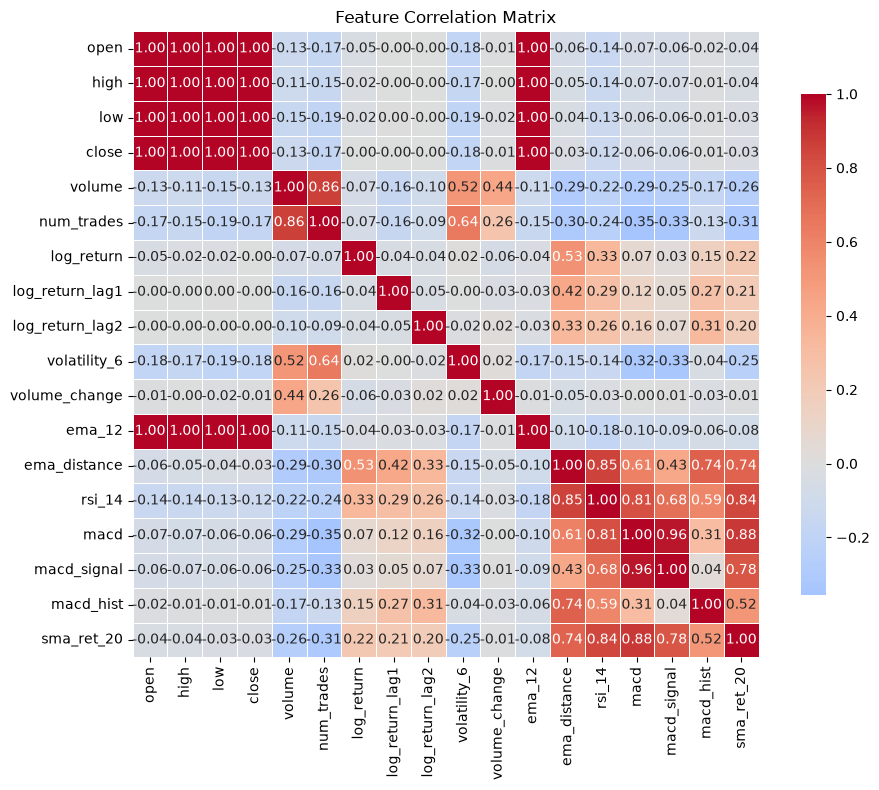

In [111]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix (only numeric columns, drop timestamp)
corr = df.drop(columns=['open_time']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [112]:
# ── feature setup: only predictors, no target leakage ─────────────────
feature_cols = [
    "log_return_lag2",
    "log_return_lag1",
    "volatility_6",
    "volume_change",
    "ema_distance",
    "rsi_14",
    "macd_hist",
    "sma_ret_20"
]

TARGET = "log_return"

# Build X and y separately
X = df[feature_cols].to_numpy(dtype=np.float32)
y = df[TARGET].to_numpy(dtype=np.float32)

# ── time-based split ─────────────────────────────────────────────────
train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train_full = X[:train_end]
X_val_full = X[train_end:val_end]
X_test_full = X[val_end:]

y_train_full = y[:train_end]
y_val_full = y[train_end:val_end]
y_test_full = y[val_end:]

# Fit normalization on training set only
feature_mean = X_train_full.mean(axis=0)
feature_std = X_train_full.std(axis=0)
feature_std[feature_std == 0] = 1.0

X_train = (X_train_full - feature_mean) / feature_std
X_val = (X_val_full - feature_mean) / feature_std
X_test = (X_test_full - feature_mean) / feature_std

# Optional: normalize target too, but do it separately
target_mean = y_train_full.mean()
target_std = y_train_full.std()
if target_std == 0:
    target_std = 1.0

y_train = (y_train_full - target_mean) / target_std
y_val = (y_val_full - target_mean) / target_std
y_test = (y_test_full - target_mean) / target_std

# ── sequence windows: X[t-window:t], y[t] ───────────────────────────
def make_windows(X_seq, y_seq, seq_len=10):
    Xw, yw = [], []
    for i in range(len(X_seq) - seq_len):
        Xw.append(X_seq[i:i + seq_len])
        yw.append(y_seq[i + seq_len])   # next step target
    return np.asarray(Xw, dtype=np.float32), np.asarray(yw, dtype=np.float32)

X_train, y_train = make_windows(X_train, y_train, seq_len=10)
X_val, y_val = make_windows(X_val, y_val, seq_len=10)
X_test, y_test = make_windows(X_test, y_test, seq_len=10)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("first target samples:", y_train[:5])

X_train: (1488, 10, 8)  y_train: (1488,)
first target samples: [-0.1948254  -0.4860858  -0.86652803  0.1658985  -0.4649198 ]


In [113]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

train_data_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_data_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [114]:
class Model(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=2, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.dropout(out[:, -1, :])
        return self.head(out)

In [115]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epoch, num_epochs,training_loss,testing_loss):
    model.train()
    train_loss = 0.0

    for feature, label in train_loader:
        optimizer.zero_grad()
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    training_loss.append(avg_train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for feature, label in val_loader:
            pred = model(feature).squeeze(-1)
            loss = criterion(pred, label)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    testing_loss.append(avg_val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs} - train_loss: {avg_train_loss:.6f} - val_loss: {avg_val_loss:.6f}")

In [116]:
model = Model(X_train.shape[-1], hidden_size=5, num_layers=1)
model

Model(
  (gru): GRU(8, 5, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=5, out_features=1, bias=True)
)

Epoch 1/100 - train_loss: 1.014261 - val_loss: 0.430885
Epoch 2/100 - train_loss: 0.995156 - val_loss: 0.431916
Epoch 3/100 - train_loss: 0.992001 - val_loss: 0.444357
Epoch 4/100 - train_loss: 0.996655 - val_loss: 0.434700
Epoch 5/100 - train_loss: 0.994547 - val_loss: 0.434929
Epoch 6/100 - train_loss: 1.008371 - val_loss: 0.440061
Epoch 7/100 - train_loss: 0.995582 - val_loss: 0.434986
Epoch 8/100 - train_loss: 0.983615 - val_loss: 0.434562
Epoch 9/100 - train_loss: 0.975579 - val_loss: 0.433534
Epoch 10/100 - train_loss: 0.973955 - val_loss: 0.453072
Epoch 11/100 - train_loss: 0.969926 - val_loss: 0.429611
Epoch 12/100 - train_loss: 0.968352 - val_loss: 0.431047
Epoch 13/100 - train_loss: 0.962876 - val_loss: 0.433626
Epoch 14/100 - train_loss: 0.976671 - val_loss: 0.434293
Epoch 15/100 - train_loss: 0.966264 - val_loss: 0.439796
Epoch 16/100 - train_loss: 0.963474 - val_loss: 0.441824
Epoch 17/100 - train_loss: 0.966071 - val_loss: 0.439546
Epoch 18/100 - train_loss: 0.959566 - va

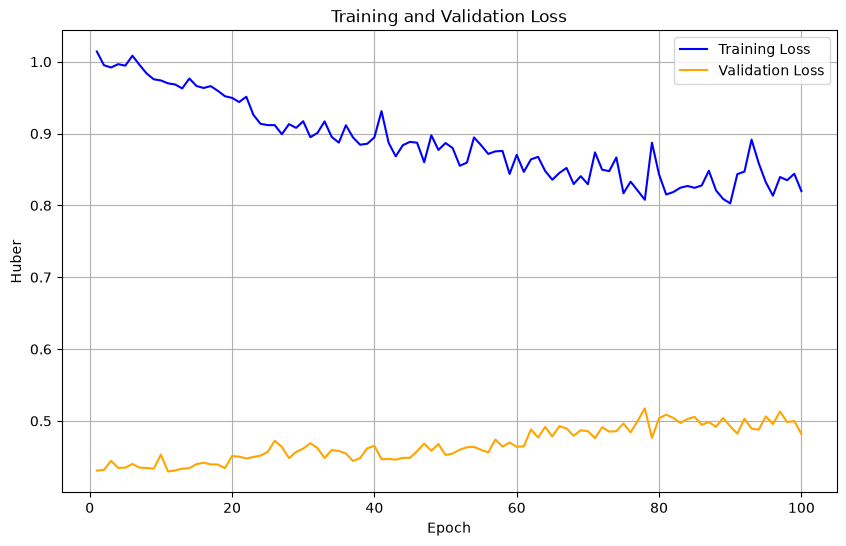

In [117]:
import matplotlib.pyplot as plt

learning_rate = 0.01
num_epochs = 100
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

training_loss = []
testing_loss = []

for epoch in range(num_epochs):
    train_model(
        model,
        train_data_loader,
        val_data_loader,
        optimizer,
        criterion,
        epoch,
        num_epochs,
        training_loss,
        testing_loss
    )

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(training_loss) + 1), training_loss, label="Training Loss", color="blue")
plt.plot(range(1, len(testing_loss) + 1), testing_loss, label="Validation Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Huber")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [118]:
model.eval()

test_loss = 0.0
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        test_loss += loss.item()

avg_test_loss = test_loss / len(test_data_loader)
print(f"Test loss: {avg_test_loss:.6f}")

Test loss: 0.458202


In [119]:
# --- 1. Gather ALL model predictions + targets on the test set ---
model.eval()
preds, actuals = [], []
with torch.no_grad():
    for feature, label in test_data_loader:
        preds.append(model(feature).squeeze(-1))
        actuals.append(label)
preds = torch.cat(preds)
actuals = torch.cat(actuals)

# --- 2. Mean baseline: predict the mean of the TRAINING target ---
baseline_value = y_train.mean()
baseline_preds = torch.full_like(actuals, float(baseline_value))

# --- 3. Evaluate both with identical metrics ---
def report(pred, target, name):
    mse = ((pred - target) ** 2).mean()
    mae = (pred - target).abs().mean()
    rmse = mse.sqrt()
    print(f"{name:>16} | RMSE: {rmse:.6f} | MAE: {mae:.6f}")

print("NORMALIZED log-return space:")
report(preds, actuals, "Model")
report(baseline_preds, actuals, "Mean baseline")

# --- 4. Undo the target scaling to real log-return space ---
pred_lr = preds * target_std + target_mean
base_lr = baseline_preds * target_std + target_mean
actual_lr = actuals * target_std + target_mean

print("\nREAL log-return space:")
report(pred_lr, actual_lr, "Model")
report(base_lr, actual_lr, "Mean baseline")

print(f"\nBaseline predicts: {float(baseline_value):.6f} (normalized)")
print(f"                 = {float(base_lr[0]):.6f} log return")


NORMALIZED log-return space:
           Model | RMSE: 0.685490 | MAE: 0.484135
   Mean baseline | RMSE: 0.642070 | MAE: 0.437968

REAL log-return space:
           Model | RMSE: 0.003238 | MAE: 0.002287
   Mean baseline | RMSE: 0.003033 | MAE: 0.002069

Baseline predicts: -0.001587 (normalized)
                 = -0.000166 log return


In [120]:
#M

In [121]:
'''
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "learning_rate": learning_rate,
    "num_epochs": num_epochs,
    "mean": mean,
    "std": std,
    "price_mean": price_mean,
    "price_std": price_std,
    "training_loss": training_loss,
    "testing_loss": testing_loss,
    "rmse_usd": rmse,
    "mae_usd": mae
}, "bitcoin_lstm_model.pt")

'''

'\ntorch.save({\n    "model_state_dict": model.state_dict(),\n    "optimizer_state_dict": optimizer.state_dict(),\n    "learning_rate": learning_rate,\n    "num_epochs": num_epochs,\n    "mean": mean,\n    "std": std,\n    "price_mean": price_mean,\n    "price_std": price_std,\n    "training_loss": training_loss,\n    "testing_loss": testing_loss,\n    "rmse_usd": rmse,\n    "mae_usd": mae\n}, "bitcoin_lstm_model.pt")\n\n'

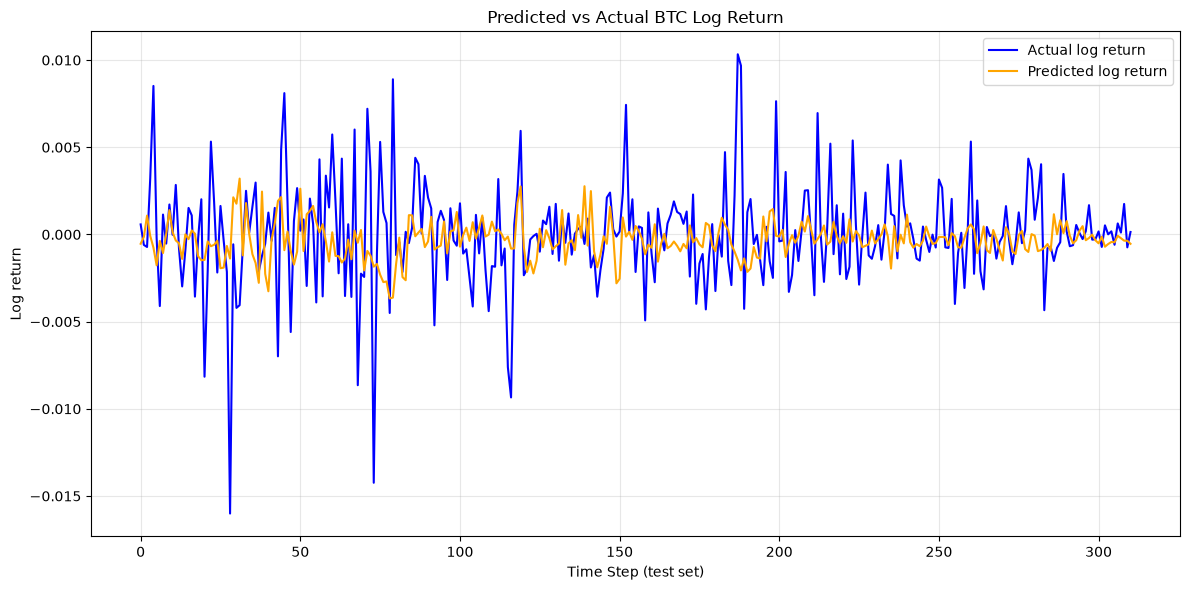

In [122]:
import matplotlib.pyplot as plt

# Convert back to real log return space
pred_logret = preds * target_std + target_mean
actual_logret = actuals * target_std + target_mean

plt.figure(figsize=(12, 6))
plt.plot(actual_logret.numpy(), label="Actual log return", color="blue", linewidth=1.5)
plt.plot(pred_logret.numpy(), label="Predicted log return", color="orange", linewidth=1.5)
plt.xlabel("Time Step (test set)")
plt.ylabel("Log return")
plt.title("Predicted vs Actual BTC Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [123]:
model.eval()

# compare to a simple persistence baseline: last observed value in each input window
all_preds = []
all_true = []
all_prev = []

with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        all_preds.append(pred.cpu().numpy())
        all_true.append(label.cpu().numpy())
        all_prev.append(feature[:, -1, -1].cpu().numpy())

all_preds = np.concatenate(all_preds)
all_true = np.concatenate(all_true)
all_prev = np.concatenate(all_prev)

# restore real target scale for interpretation
pred_lr = all_preds * target_std + target_mean
true_lr = all_true * target_std + target_mean
prev_lr = all_prev * target_std + target_mean

rmse = np.sqrt(np.mean((pred_lr - true_lr) ** 2))
mae = np.mean(np.abs(pred_lr - true_lr))

persist_rmse = np.sqrt(np.mean((prev_lr - true_lr) ** 2))
persist_mae = np.mean(np.abs(prev_lr - true_lr))

beats_persistence = np.mean(np.abs(pred_lr - true_lr) < np.abs(prev_lr - true_lr))

print(f"Model RMSE: {rmse:.6f} | MAE: {mae:.6f}")
print(f"Persistence baseline RMSE: {persist_rmse:.6f} | MAE: {persist_mae:.6f}")
print(f"Model beats persistence on {beats_persistence * 100:.1f}% of test windows")

print("\n  Prev log return | Predicted | Actual")
for p, t, prev in zip(pred_lr[:8], true_lr[:8], prev_lr[:8]):
    print(f"  {prev: .6f}   | {p: .6f} | {t: .6f}")


Model RMSE: 0.003238 | MAE: 0.002287
Persistence baseline RMSE: 0.004545 | MAE: 0.003515
Model beats persistence on 64.0% of test windows

  Prev log return | Predicted | Actual
   0.002161   | -0.000535 |  0.000575
   0.002031   | -0.000139 | -0.000600
   0.002025   |  0.001080 | -0.000719
   0.001281   | -0.000086 |  0.003227
   0.002336   | -0.000752 |  0.008516
   0.004350   | -0.001769 | -0.000194
   0.004175   | -0.000367 | -0.004107
   0.003184   | -0.001069 |  0.001139


said UP,    was UP:   64
said UP,    was DOWN: 68
said DOWN,  was UP:   101
said DOWN,  was DOWN: 78
precision of UP calls: 48.5%   <-- 'when I said up, how often was I right'
base rate (hours that were actually up): 53.1%
overall accuracy: 45.7%


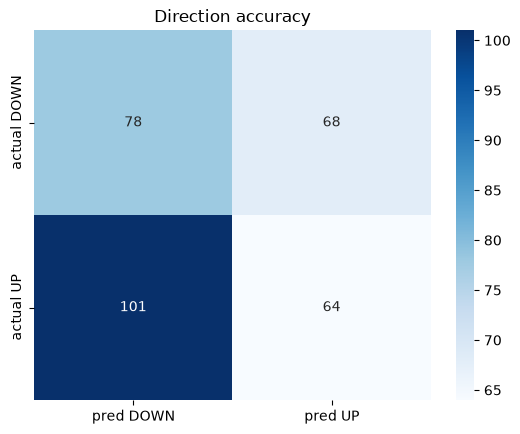

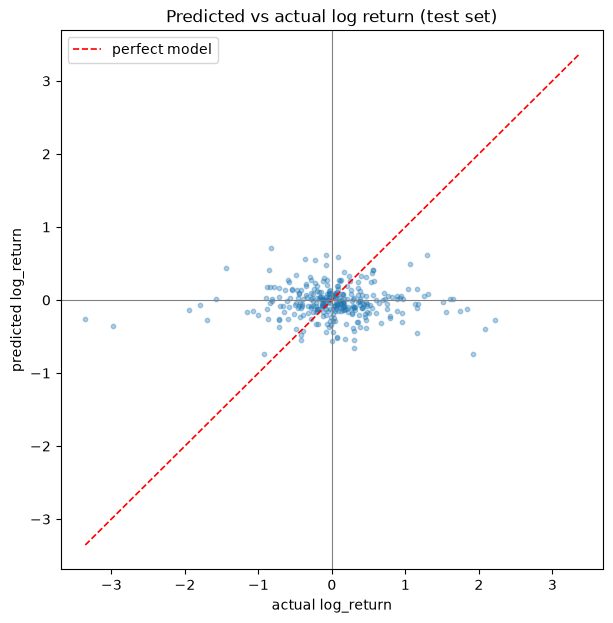

In [124]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
preds = np.asarray(preds)      # your predicted log returns
actuals = np.asarray(actuals)  # your actual log returns
 
pred_up = preds > 0
actual_up = actuals > 0
 
# ── your question, as numbers ──
tp = (pred_up & actual_up).sum()     # said UP   -> was UP
fp = (pred_up & ~actual_up).sum()    # said UP   -> was DOWN
fn = (~pred_up & actual_up).sum()    # said DOWN -> was UP
tn = (~pred_up & ~actual_up).sum()   # said DOWN -> was DOWN
 
print(f"said UP,    was UP:   {tp}")
print(f"said UP,    was DOWN: {fp}")
print(f"said DOWN,  was UP:   {fn}")
print(f"said DOWN,  was DOWN: {tn}")
print(f"precision of UP calls: {tp/(tp+fp):.1%}   <-- 'when I said up, how often was I right'")
print(f"base rate (hours that were actually up): {(actuals > 0).mean():.1%}")
print(f"overall accuracy: {(tp+tn)/len(preds):.1%}")
 
# ── your question, as a picture: confusion matrix ──
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["pred DOWN", "pred UP"],
            yticklabels=["actual DOWN", "actual UP"])
plt.title("Direction accuracy")
plt.show()
 
# ── the big picture: predicted vs actual ──
plt.figure(figsize=(7, 7))
plt.scatter(actuals, preds, alpha=0.35, s=10)
lim = max(abs(actuals.min()), abs(actuals.max()),
          abs(preds.min()), abs(preds.max()))
plt.plot([-lim, lim], [-lim, lim], "r--", lw=1.2, label="perfect model")
plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("actual log_return")
plt.ylabel("predicted log_return")
plt.legend()
plt.title("Predicted vs actual log return (test set)")
plt.show()

Real log-return space:
           Model | RMSE: 0.003238 | MAE: 0.002287
     Persistence | RMSE: 0.004545 | MAE: 0.003515


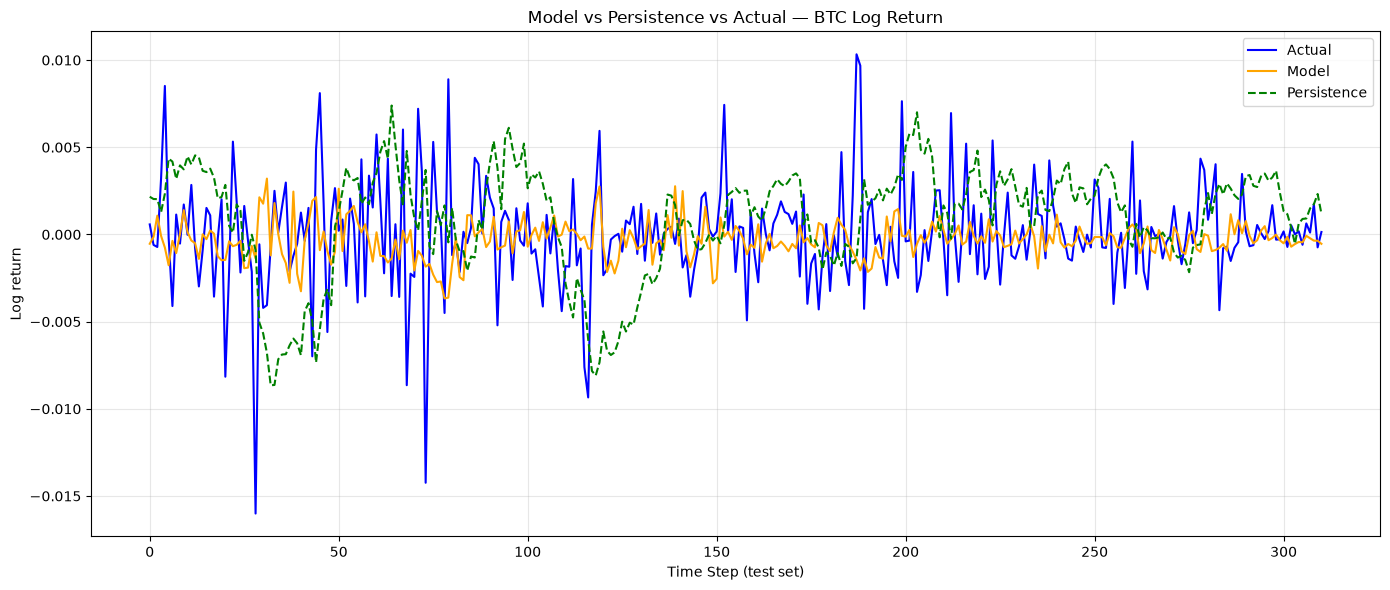

In [128]:
import matplotlib.pyplot as plt

# model predictions in real log-return space
pred_logret = preds * target_std + target_mean
actual_logret = actuals * target_std + target_mean

# persistence baseline: last observed log_return in each window
persist_logret = X_test[:, -1, -1] * target_std + target_mean

# Metrics
def metrics(pred, actual, name):
    rmse = np.sqrt(((pred - actual) ** 2).mean())
    mae = np.abs(pred - actual).mean()
    print(f"{name:>16} | RMSE: {rmse:.6f} | MAE: {mae:.6f}")

print("Real log-return space:")
metrics(np.array(pred_logret), np.array(actual_logret), "Model")
metrics(persist_logret, np.array(actual_logret), "Persistence")

# Plot
plt.figure(figsize=(14, 6))
plt.plot(np.array(actual_logret), label="Actual", color="blue", linewidth=1.5)
plt.plot(np.array(pred_logret), label="Model", color="orange", linewidth=1.5)
plt.plot(persist_logret, label="Persistence", color="green", linewidth=1.5, linestyle="--")
plt.xlabel("Time Step (test set)")
plt.ylabel("Log return")
plt.title("Model vs Persistence vs Actual — BTC Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
